# Segmentacja klientów sklepu internetowego metodą K-means

**Cel:** sprawdzić, czy na podstawie zachowań zakupowych można wyróżnić interpretowalne segmenty klientów.

Pytania pomocnicze:
1. Jak różnią się klienci pod względem częstotliwości i wartości zakupów?
2. Ile segmentów jest uzasadnione w świetle wybranych metryk i interpretacji?
3. Czym charakteryzują się uzyskane segmenty i jakie są ograniczenia wnioskowania?

Cała logika (wczytanie, czyszczenie, cechy, segmentacja, wykresy) znajduje się w pakiecie `analiza/`.
Notebook, aplikacja Streamlit i testy korzystają z tych samych funkcji.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

KATALOG_PROJEKTU = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(KATALOG_PROJEKTU))
KATALOG_WYKRESOW = KATALOG_PROJEKTU / "figures"

import pandas as pd

from analiza import czyszczenie, eda, wykresy
from analiza.wczytanie import URL_OPISU, opis_zbioru, slownik_kolumn, wczytaj_dane



def format_liczby(x: float) -> str:
    # liczby w tabelach w zapisie polskim: spacja tysięcy, przecinek dziesiętny
    if float(x).is_integer():
        return f"{x:,.0f}".replace(",", " ")
    cyfry = 3 if abs(x) < 10 else 2
    return f"{x:,.{cyfry}f}".replace(",", " ").replace(".", ",")


pd.set_option("display.float_format", format_liczby)
pd.set_option("display.max_colwidth", 120)

## 1. Opis danych

**Źródło:** UCI Machine Learning Repository – zbiór *Online Retail* (licencja CC BY 4.0).
Zawiera wszystkie transakcje brytyjskiego sklepu internetowego sprzedającego upominki
(wielu klientów to hurtownicy). **Jednostka obserwacji** w danych surowych to jedna pozycja
faktury (produkt na fakturze); jednostką analizy w segmentacji będzie **klient**.

In [2]:
surowe = wczytaj_dane()
print("Źródło:", URL_OPISU)
pd.Series(opis_zbioru(surowe), name="wartość").to_frame()

Źródło: https://archive.ics.uci.edu/dataset/352/online+retail


,wartość
liczba_wierszy,541909
liczba_kolumn,8
data_od,2010-12-01 08:26:00
data_do,2011-12-09 12:50:00
liczba_faktur,25900
liczba_klientow,4372
liczba_produktow,4070
liczba_krajow,38


In [3]:
slownik_kolumn(surowe)

,kolumna,typ,przyklad,znaczenie
0,InvoiceNo,str,536365,Numer faktury (6 cyfr); prefiks 'C' oznacza fakturę anulującą (korektę)
1,StockCode,str,85123A,"Kod produktu (5 cyfr, czasem z literą); kody specjalne, np. POST, M, D, oznaczają pozycje nietowarowe"
2,Description,str,WHITE HANGING HEART T-LIGHT HOLDER,Nazwa produktu
3,Quantity,int64,6,"Liczba sztuk w pozycji faktury; wartości ujemne to anulowania, zwroty i korekty"
4,InvoiceDate,datetime64[us],2010-12-01 08:26:00,Data i godzina wystawienia faktury
5,UnitPrice,float64,2.55,Cena jednostkowa w funtach szterlingach (GBP)
6,CustomerID,Int64,17850,Pięciocyfrowy identyfikator klienta
7,Country,str,United Kingdom,Kraj zamieszkania klienta


In [4]:
surowe.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,"2,550",17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,"3,390",17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,"2,750",17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,"3,390",17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,"3,390",17850,United Kingdom


Zbiór obejmuje ok. 12 miesięcy (01.12.2010–09.12.2011), 541 909 pozycji faktur w 8 kolumnach,
25 900 faktur, 4 372 klientów, 4 070 kodów produktów i 38 krajów. Kluczowe pola dla segmentacji to
`CustomerID` (kto), `InvoiceNo` i `InvoiceDate` (kiedy i w ramach którego zamówienia) oraz
`Quantity` × `UnitPrice` (ile wydał).

## 2. Kontrola jakości danych

Sprawdzamy typy, braki, duplikaty oraz wartości niedozwolone i nietypowe.

In [5]:
czyszczenie.raport_jakosci(surowe)

,typ,braki,braki_proc,unikalne,min,max
kolumna,,,,,,
InvoiceNo,str,0,0,25900,None,None
StockCode,str,0,0,4070,None,None
Description,str,1454,"0,270",4211,None,None
Quantity,int64,0,0,722,-80995,80995
InvoiceDate,datetime64[us],0,0,23260,2010-12-01 08:26:00,2011-12-09 12:50:00
UnitPrice,float64,0,0,1630,"-11 062,06",38 970
CustomerID,Int64,135080,"24,93",4372,12346,18287
Country,str,0,0,38,None,None


In [6]:
czyszczenie.podsumowanie_problemow(surowe).to_frame()

,liczba
wiersze,541909
pelne duplikaty,5268
brak CustomerID,135080
brak Description,1454
wiersze faktur anulujących (C),9288
Quantity <= 0,10624
Quantity < 0 poza fakturami C,1336
UnitPrice = 0,2515
UnitPrice < 0,2
nietypowy format InvoiceNo,3


Najważniejsze problemy:

* **Brak `CustomerID`** w 135 080 wierszach (24,9%) – tych transakcji nie da się przypisać do klienta.
* **5 268 pełnych duplikatów** – ta sama faktura, produkt, ilość, cena i czas co do minuty.
* **Faktury anulujące** (numer z prefiksem `C`, 9 288 pozycji) – wszystkie mają ujemną ilość;
  w tym zbiorze zwroty i anulowania zamówień są księgowane tym samym typem dokumentu.
* **Ujemne ilości poza fakturami `C`** (1 336 wierszy) – korekty magazynowe (np. towar uszkodzony),
  wszystkie bez identyfikatora klienta i z ceną 0.
* **Ceny niedodatnie:** 2 515 pozycji z ceną 0 i 2 z ceną ujemną (korekta złego długu, faktury z prefiksem `A`).
* **Pozycje nietowarowe** – kody `POST`, `DOT`, `C2` (wysyłka), `M` (korekty ręczne), `D` (rabat),
  `BANK CHARGES`, `CRUK`, `AMAZONFEE` i inne – nie są zakupem produktu.

In [7]:
surowe.loc[czyszczenie.czy_pozycja_nietowarowa(surowe)].groupby("StockCode").agg(
    pozycje=("Quantity", "size"),
    opis=("Description", "first"),
    wartosc=("UnitPrice", lambda s: (s * surowe.loc[s.index, "Quantity"]).sum()),
).sort_values("pozycje", ascending=False)

,pozycje,opis,wartosc
StockCode,,,
POST,1256,POSTAGE,"66 230,64"
DOT,710,DOTCOM POSTAGE,"206 245,48"
M,571,Manual,"-68 674,19"
C2,144,CARRIAGE,6 986
D,77,Discount,"-5 696,22"
S,63,SAMPLES,"-3 049,39"
BANK CHARGES,37,Bank Charges,"-7 175,64"
AMAZONFEE,34,AMAZON FEE,"-221 520,50"
CRUK,16,CRUK Commission,"-7 933,43"


**Wartości nietypowe.** Największe ilości w pozycjach (80 995 i 74 215 sztuk) to zamówienia,
które zostały anulowane identyczną fakturą `C` 12 i 16 minut później – w ujęciu netto się znoszą.
Nie usuwamy ich ręcznie: anulowania pozostają w danych i zostaną odjęte przy liczeniu wartości zakupów.
Pozostałe skrajne pozycje to 12 540 sztuk z ceną 0 (odpadną przy regule ceny ≤ 0) oraz korekta magazynowa
−9 600 sztuk bez klienta.

In [8]:
kolumny = ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]
skrajne = surowe.loc[surowe["Quantity"].abs().nlargest(6).index, kolumny]
skrajne.sort_values(["CustomerID", "InvoiceDate"])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,"1,040",12346
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,"1,040",12346
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0,13256
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,"2,080",16446
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,"2,080",16446
225529,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0,<NA>


## 3. Czyszczenie danych i dziennik decyzji

Każda reguła jest osobną funkcją w `analiza/czyszczenie.py`, która nie modyfikuje danych wejściowych
i zwraca wpis do dziennika. Przyjęte decyzje:

| Problem | Decyzja | Uzasadnienie |
|---|---|---|
| pełne duplikaty | usunięcie | podwójny zapis tej samej pozycji |
| brak `CustomerID` | usunięcie | jednostką analizy jest klient |
| ilość ≤ 0 poza fakturami `C` | usunięcie | korekty magazynowe, nie zachowanie klienta |
| cena ≤ 0 | usunięcie | brak wartości zakupu (gratisy, korekty) |
| pozycje nietowarowe | usunięcie | opłaty i korekty ręczne nie opisują zakupów produktów |
| anulowania i zwroty (`C`) | **pozostawienie** i oznaczenie | pomniejszają wartość netto, nie są liczone jako zamówienia |
| wartości skrajne | **pozostawienie** | to rzeczywiste duże zamówienia (hurt); ich wpływ ograniczy transformacja cech |

In [9]:
dane, dziennik = czyszczenie.wyczysc_dane(surowe)
dziennik

,krok,dzialanie,uzasadnienie,wiersze_przed,wiersze_po,liczba_obserwacji
0,pełne duplikaty,usunięcie,"Identyczna faktura, produkt, ilość, cena i czas co do minuty – traktujemy jako podwójny zapis tej samej pozycji.",541909,536641,5268
1,brak CustomerID,usunięcie,"Bez identyfikatora nie da się przypisać transakcji do klienta, a jednostką analizy jest klient.",536641,401604,135037
2,ilość <= 0 poza fakturami C,usunięcie,"Ujemne ilości bez faktury anulującej to korekty stanów magazynowych (np. uszkodzenia), a nie zachowanie klienta.",401604,401604,0
3,cena <= 0,usunięcie,"Pozycje bez dodatniej ceny (gratisy, korekty długu) nie wnoszą wartości zakupu i zawyżałyby liczbę zamówień.",401604,401564,40
4,pozycje nietowarowe,usunięcie,"Opłaty pocztowe, bankowe, rabaty i korekty ręczne nie opisują zakupów produktów; korekty ręczne mają skrajne kwoty.",401564,399659,1905
5,oznaczenie anulowań,oznaczenie,"Anulowania i zwroty zostają w danych: pomniejszają wartość zakupów klienta (Monetary netto), ale nie są liczone jako...",399659,399659,8506
6,wartość pozycji,nowa kolumna,Wartość pozycji w GBP potrzebna do wyznaczenia Monetary.,399659,399659,399659


In [10]:
czyszczenie.porownanie_przed_po(surowe, dane)

,przed,po
wiersze,541909,399659
pelne duplikaty,5268,0
brak CustomerID,135080,0
brak Description,1454,0
wiersze faktur anulujących (C),9288,8506
Quantity <= 0,10624,8506
Quantity < 0 poza fakturami C,1336,0
UnitPrice = 0,2515,0
UnitPrice < 0,2,0
nietypowy format InvoiceNo,3,0


Po czyszczeniu zostaje 399 659 pozycji (73,7% wierszy), 21 785 faktur i 4 362 klientów.
Największą stratą jest odrzucenie transakcji bez identyfikatora klienta – to ograniczenie analizy:
nie wiemy, czy ci anonimowi kupujący zachowują się podobnie do klientów zidentyfikowanych.
241 pozycji z krajem `Unspecified` pozostaje, bo kraj nie jest cechą segmentacji.

In [11]:
czyszczenie.raport_jakosci(dane)

,typ,braki,braki_proc,unikalne,min,max
kolumna,,,,,,
InvoiceNo,str,0,0,21785,None,None
StockCode,str,0,0,3677,None,None
Description,str,0,0,3878,None,None
Quantity,int64,0,0,431,-80995,80995
InvoiceDate,datetime64[us],0,0,20132,2010-12-01 08:26:00,2011-12-09 12:50:00
UnitPrice,float64,0,0,373,"0,001","649,50"
CustomerID,Int64,0,0,4362,12346,18287
Country,str,0,0,37,None,None
Anulowanie,bool,0,0,2,False,True


## 4. Analiza eksploracyjna transakcji

### 4.1 Statystyki opisowe pozycji i faktur sprzedażowych

In [12]:
sprzedaz = dane[~dane["Anulowanie"]]
eda.statystyki_opisowe(sprzedaz, ["Quantity", "UnitPrice", "Wartosc"])

,liczebnosc,srednia,odch_std,min,Q1,mediana,Q3,max,skosnosc
Quantity,391153,"13,15","180,81",1,2,6,12,80 995,"406,82"
UnitPrice,391153,"2,874","4,285","0,001","1,250","1,950","3,750","649,50","35,69"
Wartosc,391153,"22,34","310,93","0,001","4,950","11,90","19,80","168 469,60","450,95"


In [13]:
faktury = eda.podsumowanie_faktur(dane)
eda.statystyki_opisowe(faktury, ["pozycje", "sztuki", "wartosc"])

,liczebnosc,srednia,odch_std,min,Q1,mediana,Q3,max,skosnosc
pozycje,18402,"21,26","24,35",1,7,15,27,541,"5,254"
sztuki,18402,"279,41","975,18",1,75,156,291,80 995,"56,46"
wartosc,18402,"474,80","1 678,79","0,380","157,14","301,65","463,07","168 469,60","62,50"


*Obserwacja:* typowa pozycja to 6 sztuk po 1,95 GBP (mediany), ale średnie są wyraźnie wyższe od median,
a skośność przekracza 400 dla ilości i wartości pozycji. Mediana faktury to 15 pozycji i ok. 302 GBP.

*Interpretacja:* rozkłady są silnie prawostronnie skośne – obok wielu drobnych zakupów występują
pojedyncze bardzo duże zamówienia hurtowe. Do opisu typowego klienta lepiej nadają się mediany i kwartyle
niż średnie.

### 4.2 Sprzedaż w czasie

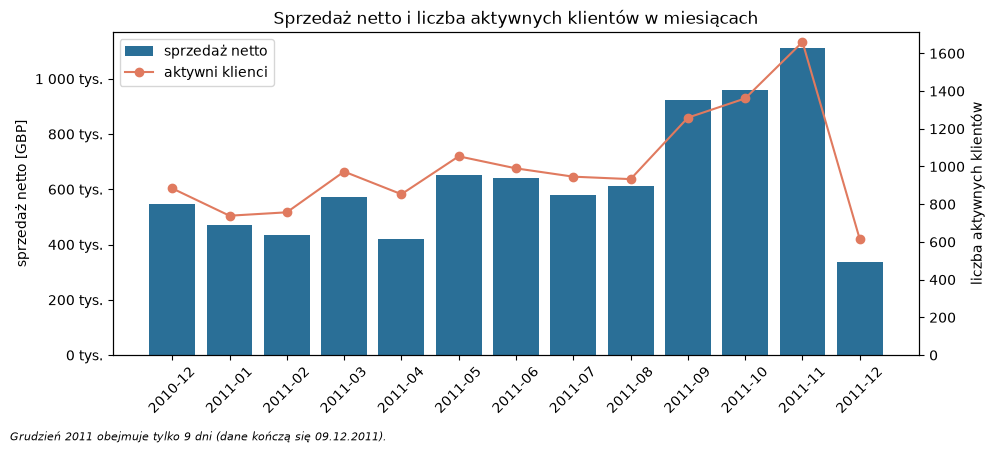

In [14]:
miesiace = eda.sprzedaz_miesieczna(dane)
fig = wykresy.wykres_sprzedazy_miesiecznej(
    miesiace, uwaga="Grudzień 2011 obejmuje tylko 9 dni (dane kończą się 09.12.2011)."
)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "01_sprzedaz_miesieczna.png")
fig

In [15]:
miesiace

,sprzedaz_brutto,anulowania,faktury,aktywni_klienci,sprzedaz_netto
miesiac,,,,,
2010-12,"565 199,56","17 305,64",1394,884,"547 893,92"
2011-01,"562 682,91","91 252,57",983,739,"471 430,34"
2011-02,"442 293,59","8 275,42",992,757,"434 018,17"
2011-03,"583 143,85","10 005,80",1312,973,"573 138,05"
2011-04,"454 440,88","33 313,11",1139,853,"421 127,77"
2011-05,"659 242,49","8 928,25",1544,1054,"650 314,24"
2011-06,"653 264,92","12 635,71",1390,990,"640 629,21"
2011-07,"591 603,79","11 389,06",1321,946,"580 214,73"
2011-08,"635 514,38","22 909,25",1267,933,"612 605,13"


*Obserwacja:* od września do listopada 2011 sprzedaż netto rośnie z ok. 0,6 do 1,1 mln GBP miesięcznie,
a liczba aktywnych klientów z ok. 930 do 1 660. Spadek w grudniu 2011 wynika z niepełnego miesiąca
(oraz anulowania zamówienia na 168 tys. GBP 9 grudnia).

*Interpretacja:* sprzedaż ma wyraźną sezonowość przedświąteczną. Ma to znaczenie dla cechy Recency liczonej
na 10.12.2011 – klienci kupujący głównie przed świętami wyglądają na „aktywnych”, a klienci sezonowi
z innych okresów mogą wyglądać na utraconych, choć wrócą w kolejnym sezonie.

### 4.3 Struktura geograficzna

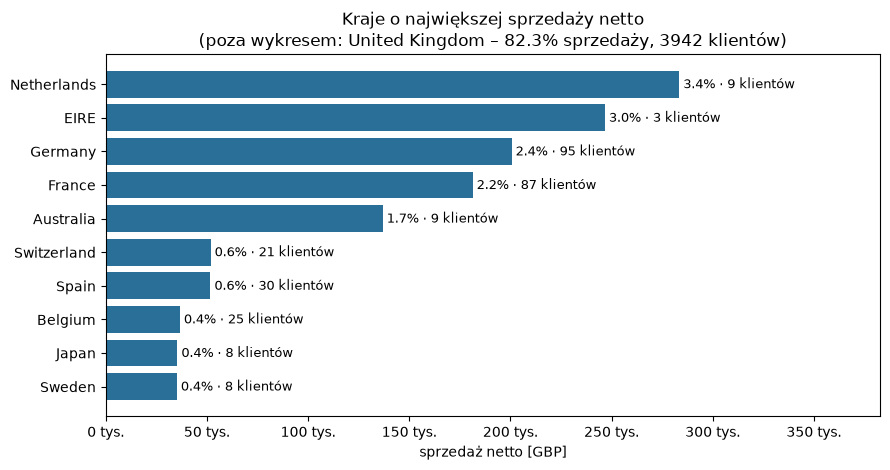

In [16]:
kraje = eda.sprzedaz_wg_kraju(dane, n=11)
fig = wykresy.wykres_krajow(kraje)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "02_kraje.png")
fig

*Obserwacja:* Wielka Brytania to 82,3% sprzedaży netto i 3 942 z 4 362 klientów (90%).
Holandia (9 klientów) i Irlandia (3 klientów) generują łącznie 6,4% sprzedaży.

*Interpretacja:* wnioski z segmentacji opisują przede wszystkim klientów brytyjskich. Wysoka sprzedaż
przy kilku klientach w niektórych krajach sugeruje odbiorców hurtowych – takie obserwacje będą
skrajne w cechach wartości.

### 4.4 Kiedy klienci składają zamówienia

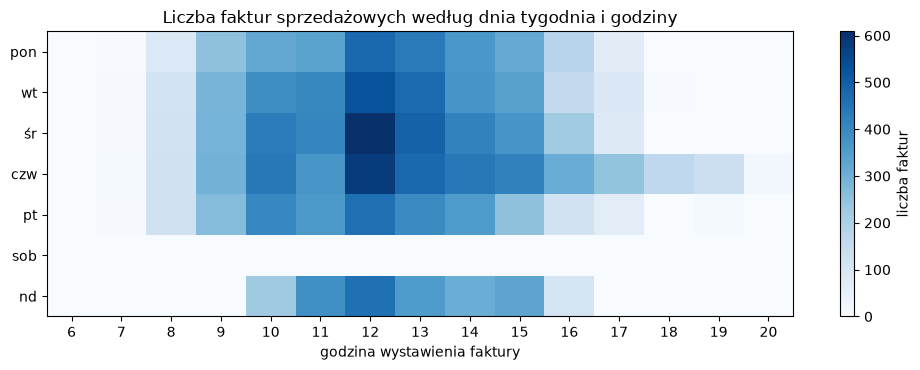

In [17]:
tydzien = eda.aktywnosc_tygodniowa(dane)
fig = wykresy.wykres_aktywnosci_tygodniowej(tydzien)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "03_aktywnosc_tygodniowa.png")
fig

*Obserwacja:* w danych nie ma żadnej faktury z soboty; zamówienia składane są w godzinach 6–20,
najczęściej około południa, w niedziele tylko między 10 a 16.

*Interpretacja:* rozkład przypomina rytm pracy firm, co jest spójne z informacją, że wielu klientów
to hurtownicy. Brak sobót to raczej cecha systemu lub organizacji sklepu niż zachowania klientów –
nie wyciągamy z niego wniosków o preferencjach.

### 4.5 Anulowania i zwroty

In [18]:
eda.udzial_anulowan(dane).to_frame("wartość [%]")

,wartość [%]
faktury_proc,"15,53"
pozycje_proc,"2,130"
wartosc_proc,"5,400"
klienci_z_anulowaniem_proc,"35,17"


*Obserwacja:* 15,5% faktur to faktury anulujące, ale korygują one tylko 5,4% wartości sprzedaży;
co trzeci klient (35%) ma co najmniej jedno anulowanie.

*Interpretacja:* anulowania są częste, ale zwykle dotyczą małych kwot. Pominięcie ich zawyżałoby wartość
części klientów (skrajny przypadek: klient 12346, którego jedyne zamówienie za 77 tys. GBP zostało
anulowane w całości), dlatego Monetary liczymy netto.

## 5. Cechy klientów (RFM)

Dane transakcyjne agregujemy do tabeli, w której **jeden wiersz to jeden klient**. Wybrano model RFM,
bo jego trzy cechy bezpośrednio odpowiadają na pytanie badawcze (kiedy, jak często i za ile klient kupuje),
są łatwe do interpretacji i dostępne dla każdego klienta. Kraj nie jest cechą segmentacji – 90% klientów
pochodzi z Wielkiej Brytanii, a zmienna kategoryczna nie pasuje do odległości euklidesowej w K-means.

| Cecha | Definicja | Uzasadnienie |
|---|---|---|
| **Recency** | liczba dni od dnia ostatniego zakupu do daty odniesienia (10.12.2011 – dzień po ostatniej transakcji) | im mniej dni, tym klient bardziej aktywny |
| **Frequency** | liczba **unikalnych faktur sprzedażowych** | jedna faktura = jedno zamówienie; liczenie pozycji zawyżałoby częstotliwość klientom kupującym wiele produktów naraz |
| **Monetary** | wartość zakupów **netto** w GBP: sprzedaż pomniejszona o anulowania i zwroty | wartość, którą klient faktycznie zostawił w sklepie |

Faktury anulujące nie zwiększają Frequency, ale pomniejszają Monetary. Recency liczymy z ostatniej
faktury sprzedażowej (anulowanie nie jest zakupem).

In [19]:
from analiza.cechy import (
    CECHY_LOG,
    CECHY_RFM,
    data_odniesienia,
    kontrola_agregacji,
    odfiltruj_klientow,
    przeksztalc_cechy,
    przygotuj_macierz_cech,
    zbuduj_rfm,
)

print("Data odniesienia:", data_odniesienia(dane).date())
klienci_wszyscy = zbuduj_rfm(dane)
klienci_wszyscy.head()

Data odniesienia: 2011-12-10


,Recency,Frequency,Monetary,Wartosc_brutto,Wartosc_zwrotow,Pierwszy_zakup,Ostatni_zakup,Kraj
CustomerID,,,,,,,,
12346,326,1,0,"77 183,60","77 183,60",2011-01-18 10:01:00,2011-01-18 10:01:00,United Kingdom
12347,3,7,4 310,4 310,0,2010-12-07 14:57:00,2011-12-07 15:52:00,Iceland
12348,76,4,"1 437,24","1 437,24",0,2010-12-16 19:09:00,2011-09-25 13:13:00,Finland
12349,19,1,"1 457,55","1 457,55",0,2011-11-21 09:51:00,2011-11-21 09:51:00,Italy
12350,311,1,"294,40","294,40",0,2011-02-02 16:01:00,2011-02-02 16:01:00,Norway


**Kontrola agregacji.** Jeżeli żadna pozycja nie została policzona podwójnie ani pominięta, suma Monetary
musi być równa wartości netto wszystkich transakcji, a suma Frequency – liczbie faktur sprzedażowych.

In [20]:
kontrola_agregacji(dane, klienci_wszyscy).to_frame()

,wartość
klienci w transakcjach,4 362
wiersze tabeli cech,4 362
faktury sprzedażowe,18 402
suma Frequency,18 402
wartość netto transakcji,"8 265 476,93"
suma Monetary,"8 265 476,93"


Sumy się zgadzają (8 265 476,93 GBP i 18 402 faktury), a tabela ma dokładnie jeden wiersz na klienta.

**Klienci bez zakupu netto.** 42 klientów nie ma dodatniej wartości zakupów: 28 ma wyłącznie faktury
anulujące (zakupy sprzed okresu obserwacji), a 14 po odjęciu anulowań ma Monetary ≤ 0 – np. klient 12346,
którego jedyne zamówienie (74 215 sztuk za 77 183,60 GBP) anulowano 16 minut później. Wyłączamy ich
z segmentacji, bo nie mają zakupu do opisania, a logarytm wartości niedodatniej jest nieokreślony.

In [21]:
klienci, wpis_klienci = odfiltruj_klientow(klienci_wszyscy)
dziennik_pelny = pd.concat([dziennik, pd.DataFrame([wpis_klienci])], ignore_index=True)
dziennik_pelny[["krok", "dzialanie", "wiersze_przed", "wiersze_po", "liczba_obserwacji"]]

,krok,dzialanie,wiersze_przed,wiersze_po,liczba_obserwacji
0,pełne duplikaty,usunięcie,541909,536641,5268
1,brak CustomerID,usunięcie,536641,401604,135037
2,ilość <= 0 poza fakturami C,usunięcie,401604,401604,0
3,cena <= 0,usunięcie,401604,401564,40
4,pozycje nietowarowe,usunięcie,401564,399659,1905
5,oznaczenie anulowań,oznaczenie,399659,399659,8506
6,wartość pozycji,nowa kolumna,399659,399659,399659
7,klienci bez zakupu netto,wyłączenie z segmentacji,4362,4320,42


In [22]:
klienci_wszyscy[klienci_wszyscy["Monetary"] <= 0].sort_values("Monetary").head(8)

,Recency,Frequency,Monetary,Wartosc_brutto,Wartosc_zwrotow,Pierwszy_zakup,Ostatni_zakup,Kraj
CustomerID,,,,,,,,
14213,NaN,0,"-1 192,20",0,"1 192,20",NaT,NaT,United Kingdom
15823,NaN,0,"-811,86",0,"811,86",NaT,NaT,United Kingdom
16742,NaN,0,"-464,90",0,"464,90",NaT,NaT,United Kingdom
16252,NaN,0,"-295,09",0,"295,09",NaT,NaT,United Kingdom
12666,NaN,0,"-227,44",0,"227,44",NaT,NaT,Israel
17307,NaN,0,"-152,64",0,"152,64",NaT,NaT,United Kingdom
17548,234,1,"-141,48","103,30","244,78",2011-04-20 12:01:00,2011-04-20 12:01:00,United Kingdom
15728,NaN,0,"-134,80",0,"134,80",NaT,NaT,United Kingdom


## 6. Analiza eksploracyjna cech klientów

### 6.1 Statystyki opisowe

In [23]:
eda.statystyki_opisowe(klienci, CECHY_RFM)

,liczebnosc,srednia,odch_std,min,Q1,mediana,Q3,max,skosnosc
Recency,4320,"93,07","100,12",1,18,51,143,374,"1,246"
Frequency,4320,"4,256","7,645",1,1,2,5,206,"11,94"
Monetary,4320,"1 914,27","8 303,78","2,900","299,05","650,42","1 610,46","278 778,02","21,54"


In [24]:
jednorazowi = (klienci["Frequency"] == 1).mean()
print(f"Klienci z jednym zamówieniem: {jednorazowi:.1%}".replace(".", ","))
klienci["Frequency"].value_counts().sort_index().head(10).to_frame("liczba klientów")

Klienci z jednym zamówieniem: 34,6%


,liczba klientów
Frequency,
1,1493
2,829
3,502
4,395
5,236
6,173
7,139
8,98
9,69


*Obserwacja:* typowy klient (mediana) kupił ostatnio 51 dni przed datą odniesienia, złożył 2 zamówienia
i wydał 650 GBP. Średnie są dużo wyższe (4,3 zamówienia, 1 914 GBP), a 34,6% klientów złożyło tylko jedno
zamówienie.

*Interpretacja:* większość klientów kupuje okazjonalnie, a o średnich decyduje niewielka grupa klientów
bardzo aktywnych. Część klientów z jednym zamówieniem mogła po prostu dołączyć pod koniec okresu – niska
Frequency nie zawsze oznacza brak lojalności.

### 6.2 Rozkłady cech

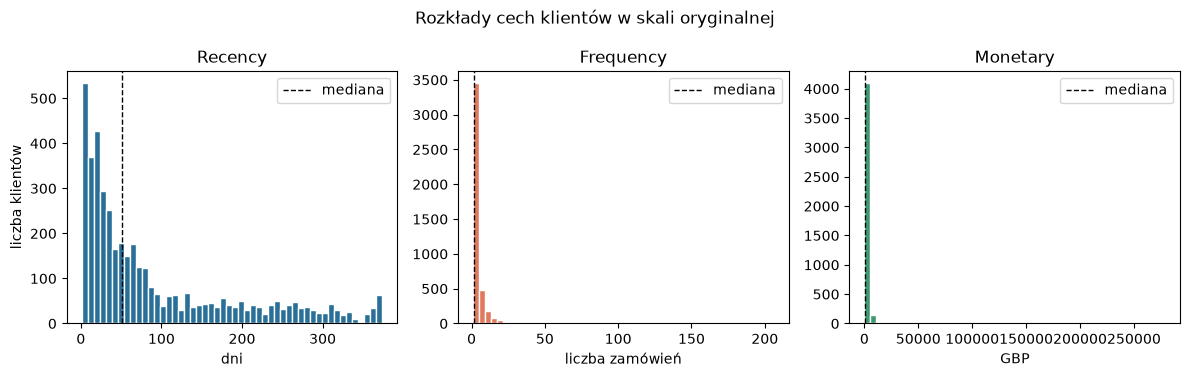

In [25]:
fig = wykresy.wykres_rozkladow(klienci, tytul="Rozkłady cech klientów w skali oryginalnej")
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "04_rozklady_rfm.png")
fig

*Obserwacja:* Recency ma rozkład malejący z długim ogonem do 374 dni; Frequency i Monetary są skupione
przy małych wartościach z bardzo długim prawym ogonem (maksima: 206 zamówień i 278 778 GBP przy medianach
2 i 650 GBP) – na wykresie w skali oryginalnej prawie wszyscy klienci mieszczą się w pierwszym słupku.

*Interpretacja:* w takiej skali odległości między klientami wyznaczałyby głównie pojedyncze skrajne
obserwacje. Przed segmentacją potrzebna jest transformacja ograniczająca wpływ ogonów.

### 6.3 Wartości odstające

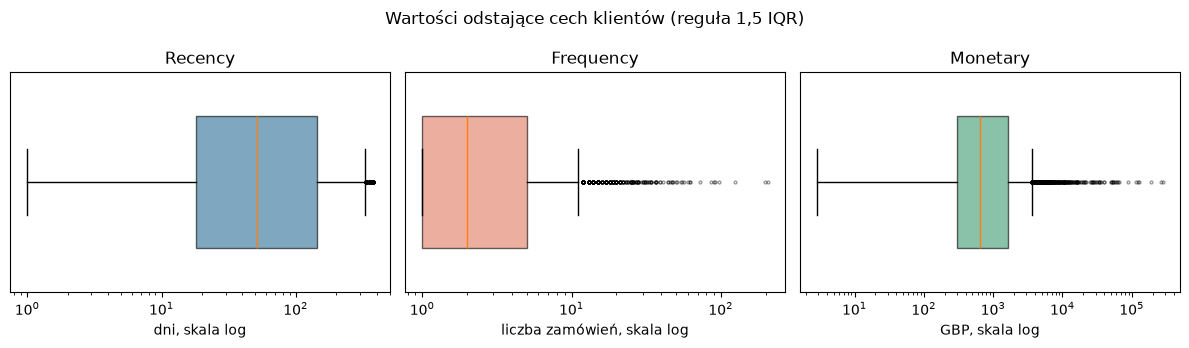

In [26]:
fig = wykresy.wykres_pudelkowy(klienci)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "05_wartosci_odstajace.png")
fig

In [27]:
czyszczenie.wartosci_skrajne(klienci, CECHY_RFM)

,Q1,Q3,dolna_granica,gorna_granica,ponizej,powyzej,odsetek_proc,max
cecha,,,,,,,,
Recency,18,143,"-169,50","330,50",0,153,"3,540",374
Frequency,1,5,-5,11,0,278,"6,440",206
Monetary,"299,05","1 610,46","-1 668,07","3 577,58",0,410,"9,490","278 778,02"


In [28]:
klienci.sort_values("Monetary", ascending=False).head(6)

,Recency,Frequency,Monetary,Wartosc_brutto,Wartosc_zwrotow,Pierwszy_zakup,Ostatni_zakup,Kraj
CustomerID,,,,,,,,
14646,2,72,"278 778,02","279 138,02",360,2010-12-20 10:09:00,2011-12-08 12:12:00,Netherlands
18102,1,60,"259 657,30","259 657,30",0,2010-12-07 16:42:00,2011-12-09 11:50:00,United Kingdom
17450,9,46,"189 575,53","194 390,79","4 815,26",2010-12-07 09:23:00,2011-12-01 13:29:00,United Kingdom
14911,2,198,"128 768,24","136 161,83","7 393,59",2010-12-01 14:05:00,2011-12-08 15:54:00,EIRE
12415,25,20,"123 638,18","124 564,53","926,35",2011-01-06 11:12:00,2011-11-15 14:22:00,Australia
14156,10,54,"113 685,77","116 560,08","2 874,31",2010-12-03 11:48:00,2011-11-30 10:54:00,EIRE


*Obserwacja:* według reguły 1,5 IQR wartości odstające ma 9,5% klientów w Monetary, 6,4% we Frequency
i 3,5% w Recency. Najcenniejsi klienci (np. 14646 z Holandii, 18102 z Wielkiej Brytanii) mają po kilkadziesiąt
zamówień i ponad 250 tys. GBP zakupów netto.

*Interpretacja:* to nie są błędy danych, tylko rzeczywiści – prawdopodobnie hurtowi – klienci, czyli
grupa szczególnie ważna dla segmentacji. **Nie usuwamy ich.** Ich wpływ na odległości ograniczamy
transformacją logarytmiczną (punkt 6.6).

### 6.4 Zależności między cechami

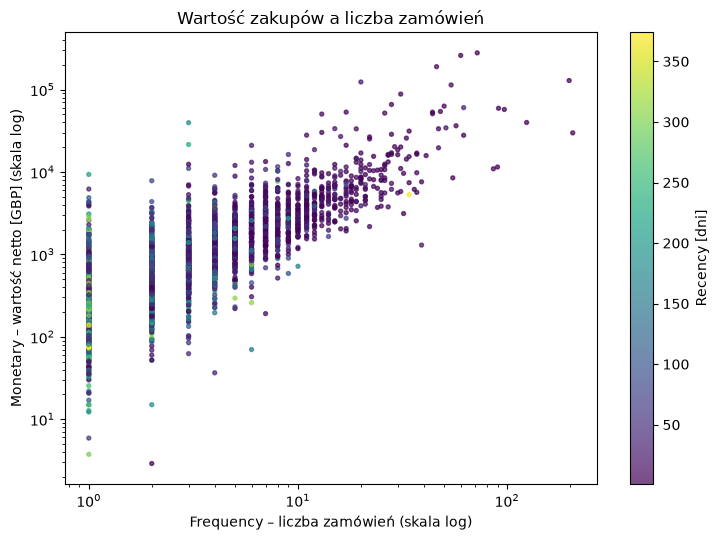

In [29]:
fig = wykresy.wykres_zaleznosci(klienci)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "06_frequency_monetary.png")
fig

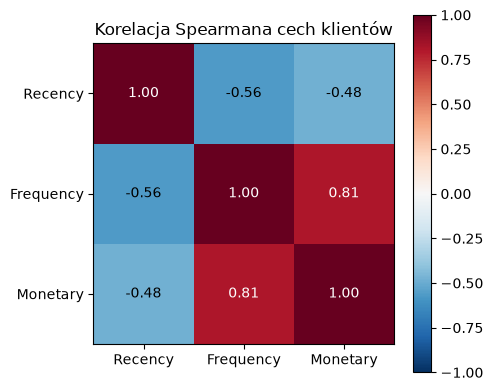

In [30]:
fig = wykresy.wykres_korelacji(eda.korelacje(klienci))
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "07_korelacje.png")
fig

In [31]:
pd.concat(
    {"Spearman": eda.korelacje(klienci), "Pearson": eda.korelacje(klienci, metoda="pearson")}, axis=1
)

Spearman                    Pearson                   
           Recency Frequency Monetary Recency Frequency Monetary
Recency          1    -0,564   -0,484       1    -0,262   -0,129
Frequency   -0,564         1    0,806  -0,262         1    0,573
Monetary    -0,484     0,806        1  -0,129     0,573        1

*Obserwacja:* korelacja Spearmana między Frequency i Monetary wynosi 0,81, a Recency jest ujemnie
skorelowana z obiema cechami (−0,56 i −0,48). Korelacje Pearsona są wyraźnie niższe (F–M 0,57),
bo zaniżają je wartości skrajne. Na wykresie rozrzutu klienci z wieloma zamówieniami mają niemal
wyłącznie niskie Recency.

*Interpretacja:* klienci, którzy kupują często, zwykle wydają więcej i kupowali niedawno – cechy w dużej
mierze opisują jeden wymiar „zaangażowania”. Należy się spodziewać, że segmenty ułożą się wzdłuż tej osi.
Korelacja opisuje współwystępowanie, a nie przyczynę.

### 6.5 Koncentracja wartości

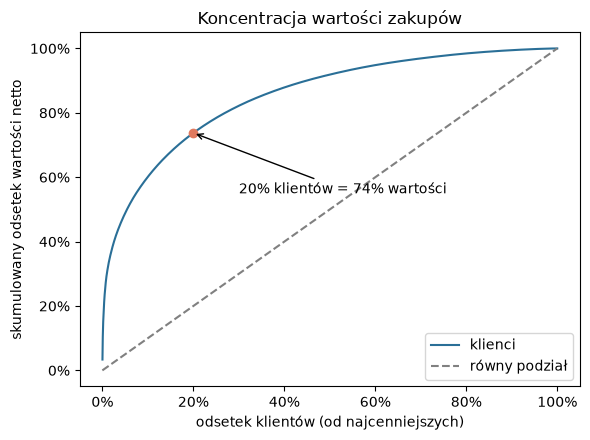

In [32]:
fig = wykresy.wykres_koncentracji(eda.koncentracja_wartosci(klienci))
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "08_koncentracja.png")
fig

In [33]:
pd.Series(
    {f"{p:.0%} najlepszych klientów": eda.udzial_najlepszych(klienci, p) for p in (0.01, 0.05, 0.2, 0.5)},
    name="udział w wartości netto",
).to_frame()

,udział w wartości netto
1% najlepszych klientów,"0,302"
5% najlepszych klientów,"0,488"
20% najlepszych klientów,"0,737"
50% najlepszych klientów,"0,919"


*Obserwacja:* 20% najcenniejszych klientów odpowiada za 74% wartości zakupów netto, a 1% klientów –
za 30%.

*Interpretacja:* baza klientów jest silnie zróżnicowana (zasada Pareto). Segmentacja ma praktyczny sens –
utrata kilku procent najlepszych klientów oznaczałaby dużą część przychodu.

### 6.6 Przekształcenie i skalowanie cech

Zgodnie z wynikami EDA:

* **Frequency i Monetary** logarytmujemy (`log1p`) – mają skrajną skośność (11,9 i 21,5), a logarytm
  zachowuje kolejność klientów i nie usuwa żadnej obserwacji;
* **Recency** zostaje w dniach – ma umiarkowaną skośność (1,25) i ograniczony zakres (1–374 dni);
  logarytm nadmiernie rozróżniałby klientów z ostatnich kilku dni.

Rozważane alternatywy (logarytm wszystkich cech, winsoryzacja, brak transformacji) porównujemy
w części dotyczącej K-means.

In [34]:
X_przed = przeksztalc_cechy(klienci)
pd.DataFrame({"skośność przed": klienci[CECHY_RFM].skew(), "skośność po": X_przed.skew()})

,skośność przed,skośność po
Recency,"1,246","1,246"
Frequency,"11,94","1,211"
Monetary,"21,54","0,365"


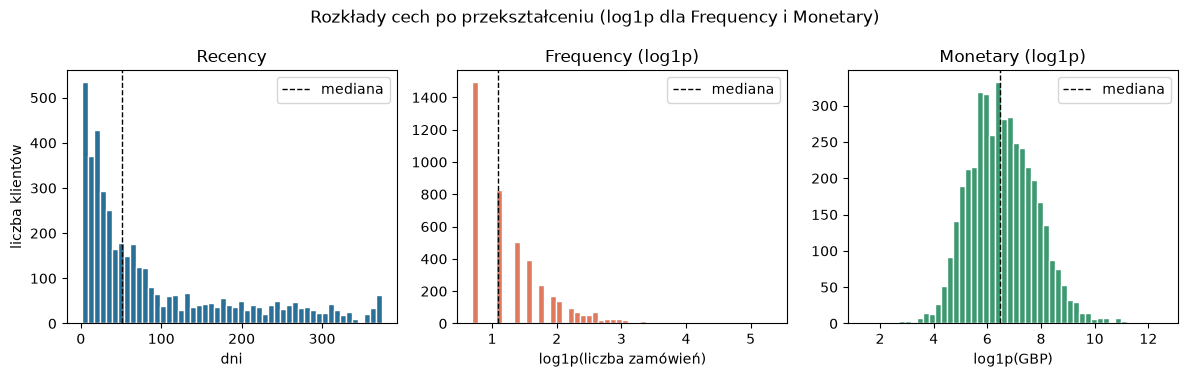

In [35]:
fig = wykresy.wykres_rozkladow(
    X_przed, tytul="Rozkłady cech po przekształceniu (log1p dla Frequency i Monetary)", log=CECHY_LOG
)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "09_rozklady_po_transformacji.png")
fig

**Skalowanie.** K-means przypisuje klientów do najbliższego centroidu w sensie odległości euklidesowej,
więc cecha o największym rozrzucie liczbowym zdominowałaby wynik. Po transformacji Recency ma wariancję
rzędu 10 000 (dni²), a logarytmy F i M – poniżej 2:

In [36]:
wariancje = X_przed.var()
pd.DataFrame({"wariancja": wariancje, "udział w sumie wariancji [%]": 100 * wariancje / wariancje.sum()})

,wariancja,udział w sumie wariancji [%]
Recency,"10 023,80","99,98"
Frequency,"0,465","0,005"
Monetary,"1,561","0,016"


Bez skalowania Recency odpowiadałaby za ponad 99,9% sumy wariancji, a segmentacja w praktyce
dzieliłaby klientów tylko według czasu od ostatniego zakupu. `StandardScaler` sprowadza każdą cechę
do średniej 0 i odchylenia 1, dzięki czemu wszystkie trzy cechy mają równy wpływ na odległości.
Skaler dopasowujemy **wyłącznie** do 4 320 klientów użytych w segmentacji.

In [37]:
X, skaler = przygotuj_macierz_cech(klienci)
pd.DataFrame(
    {"średnia (skaler)": skaler.mean_, "odchylenie (skaler)": skaler.scale_,
     "średnia po": X.mean(), "odchylenie po": X.std(ddof=0)},
    index=X.columns,
)

,średnia (skaler),odchylenie (skaler),średnia po,odchylenie po
Recency,"93,07","100,11","0,000",1
Frequency,"1,344","0,682","0,000",1
Monetary,"6,555","1,249","-0,000",1


### 6.7 Wnioski z analizy eksploracyjnej

1. **Koncentracja wartości.** *Obserwacja:* 20% klientów generuje 74% wartości netto, 1% – 30%.
   *Interpretacja:* klienci są bardzo zróżnicowani; warto wyodrębnić małą grupę kluczowych klientów,
   a cechy wartości trzeba przekształcić, żeby nie zdominowały segmentacji.
2. **Klienci okazjonalni.** *Obserwacja:* 34,6% klientów złożyło jedno zamówienie, mediana Frequency wynosi 2.
   *Interpretacja:* duża część bazy to klienci jednorazowi lub nowi – naturalny kandydat na osobny segment;
   przy rocznym okresie obserwacji nie da się jednak odróżnić klienta „nowego” od „utraconego po jednym zakupie”.
3. **Jeden wymiar zaangażowania.** *Obserwacja:* F i M są silnie skorelowane (Spearman 0,81), a obie maleją
   wraz z Recency. *Interpretacja:* segmenty będą się różnić przede wszystkim ogólnym poziomem aktywności
   i wartości; trzy cechy nie są od siebie niezależne.
4. **Sezonowość.** *Obserwacja:* sprzedaż we wrześniu–listopadzie 2011 jest 1,5–2,5 raza wyższa niż w lutym.
   *Interpretacja:* Recency liczona tuż po sezonie przedświątecznym faworyzuje klientów sezonowych;
   wyniki mogłyby wyglądać inaczej przy innej dacie odniesienia.
5. **Rynek brytyjski.** *Obserwacja:* 90% klientów i 82% sprzedaży pochodzi z Wielkiej Brytanii.
   *Interpretacja:* wnioski opisują głównie klientów brytyjskich i nie muszą przenosić się na inne rynki.

## 7. Segmentacja K-means

K-means dzieli klientów na $k$ grup, minimalizując sumę kwadratów odległości obserwacji od centroidów
ich klastrów (inercję):

$$J = \sum_{i=1}^{n} \lVert x_i - \mu_{c_i} \rVert^2 .$$

Algorytm naprzemiennie przypisuje klientów do najbliższego centroidu i przelicza centroidy. Wynik zależy
od punktów startowych, dlatego model jest uruchamiany `n_init = 10` razy (wybierane jest rozwiązanie
o najmniejszej inercji), a `random_state = 42` zapewnia odtwarzalność. Model działa na cechach po
transformacji i standaryzacji (macierz `X`: 4 320 klientów × 3 cechy).

Do porównania wartości $k = 2, \dots, 8$ używamy:

* **inercji** (metoda łokcia),
* **współczynnika silhouette** – dla klienta $i$: $s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$,
  gdzie $a(i)$ to średnia odległość do klientów z własnego klastra, a $b(i)$ – najmniejsza średnia
  odległość do klientów innego klastra; raportujemy średnią po wszystkich 4 320 klientach
  (zbiór jest na tyle mały, że próbkowanie nie jest potrzebne),
* pomocniczo **indeksu Daviesa–Bouldina** (im mniej, tym lepiej) i **stabilności** podziału:
  model dopasowany do 20 prób bootstrapowych przypisuje wszystkich klientów, a skorygowany indeks Randa
  (ARI) mierzy zgodność z podziałem z pełnych danych (1 = identyczny podział).

In [38]:
from analiza.segmentacja import (
    NAZWY_SEGMENTOW,
    RANDOM_STATE,
    WYBRANE_K,
    dodatkowy_profil,
    opisz_segmenty,
    porownaj_k,
    porownaj_warianty,
    profiluj_segmenty,
    rzut_pca,
    segmentuj,
    stabilnosc_k,
)

porownanie = porownaj_k(X)
porownanie["spadek_inercji_proc"] = 100 * (1 - porownanie["inertia"] / porownanie["inertia"].shift(1))
stabilnosc = stabilnosc_k(X, liczba_prob=20)
porownanie.join(stabilnosc)

,inertia,silhouette,davies_bouldin,najmniejszy_klaster,najmniejszy_klaster_proc,spadek_inercji_proc,ari_srednie,ari_min
k,,,,,,,,
2,"6 836,00","0,406","0,916",1825,"42,25",NaN,"0,965","0,924"
3,"4 270,08","0,415","0,826",978,"22,64","37,54","0,976","0,940"
4,"3 211,24","0,381","0,855",546,"12,64","24,80","0,935","0,768"
5,"2 732,12","0,344","0,941",314,"7,269","14,92","0,949","0,898"
6,"2 367,20","0,331","0,977",286,"6,620","13,36","0,868","0,670"
7,"2 139,02","0,301","1,017",200,"4,630","9,639","0,693","0,436"
8,"1 937,14","0,300","1,004",169,"3,912","9,438","0,807","0,616"


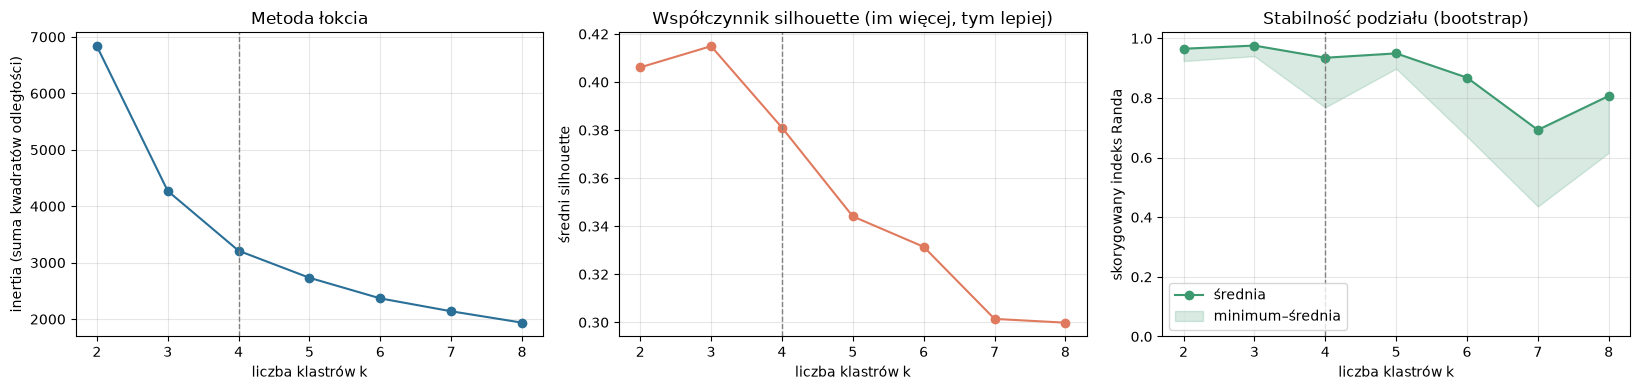

In [39]:
fig = wykresy.wykres_wyboru_k(porownanie, wybrane_k=WYBRANE_K, stabilnosc=stabilnosc)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "10_wybor_k.png")
fig

*Obserwacje:*

* Inercja maleje z każdym kolejnym klastrem (tak jest zawsze), ale największe spadki dają przejścia
  do k = 3 (−37,5%) i k = 4 (−24,8%); od k = 5 każdy klaster obniża inercję o mniej niż 15% – „łokieć”
  wypada w okolicy k = 3–4.
* Silhouette jest najwyższy dla k = 3 (0,415), nieco niższy dla k = 2 (0,406) i k = 4 (0,381),
  a od k = 5 spada do 0,30. Wartości około 0,4 oznaczają umiarkowaną strukturę: klastry są rozróżnialne,
  ale nie są od siebie wyraźnie oddzielone.
* Indeks Daviesa–Bouldina jest najniższy dla k = 3 (0,826), a dla k = 4 wynosi 0,855.
* Podziały dla k = 2–5 są stabilne (średni ARI ≥ 0,93); od k = 6 stabilność wyraźnie spada,
  więc tak drobne podziały zależą od konkretnej próby klientów.

### 7.2 Wrażliwość wyniku na przygotowanie cech

Sprawdzamy, jak metryki zmieniłyby się przy innych decyzjach dotyczących wartości skrajnych.

In [40]:
warianty = porownaj_warianty(
    klienci,
    {
        "log1p F i M (przyjęty)": {},
        "log1p R, F i M": {"log": True},
        "winsoryzacja 1–99%": {"log": False, "winsoryzacja": (0.01, 0.99)},
        "bez transformacji": {"log": False},
    },
)
warianty[["silhouette", "najmniejszy_klaster"]].unstack(level="wariant")

silhouette                                    \
wariant log1p F i M (przyjęty) log1p R, F i M winsoryzacja 1–99%   
k                                                                  
2                        0,406          0,432              0,651   
3                        0,415          0,339              0,538   
4                        0,381          0,334              0,524   
5                        0,344          0,318              0,461   
6                        0,331          0,316              0,444   
7                        0,301          0,303              0,423   
8                        0,300          0,297              0,427   

                             najmniejszy_klaster                 \
wariant bez transformacji log1p F i M (przyjęty) log1p R, F i M   
k                                                                 
2                   0,903                   1825           1654   
3                   0,591                    978            742   
4                   0,613                    546            706   
5                   0,600                    314            362   
6                   0,597                    286            273   
7                   0,517                    200            195   
8                   0,478                    169            194   

                                              
wariant winsoryzacja 1–99% bez transformacji  
k                                             
2                      330                22  
3                      264                22  
4                      137                 6  
5                       81                 3  
6                       80                 2  
7                       69                 3  
8                       49                 2

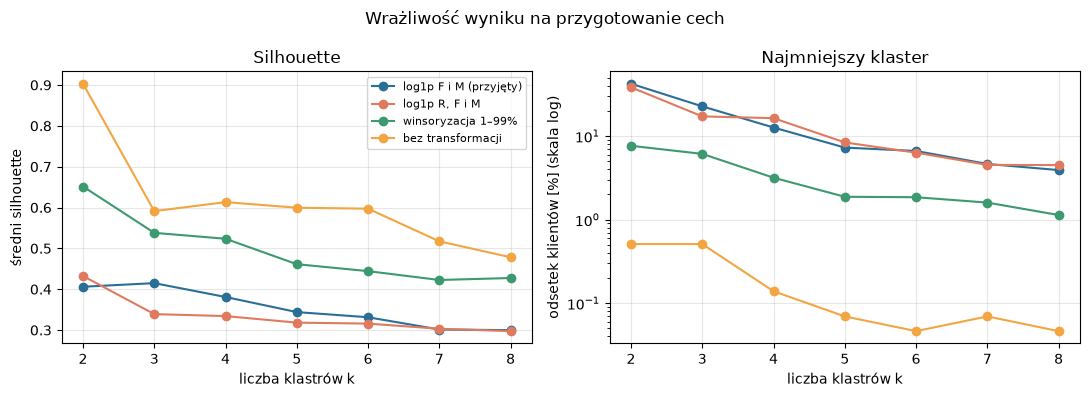

In [41]:
fig = wykresy.wykres_wariantow(warianty)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "11_warianty_cech.png")
fig

*Obserwacja:* najwyższy silhouette (0,90 dla k = 2) daje model **bez transformacji**, ale jego mniejszy
klaster liczy 22 klientów (0,5%), a przy k = 4–6 najmniejsze klastry mają 2–6 klientów. Winsoryzacja
podnosi silhouette do 0,52–0,65, ale najmniejsze klastry to 1–8% klientów. Logarytm wszystkich trzech
cech daje maksimum silhouette dla k = 2 i niższe wartości dla k ≥ 3.

*Interpretacja:* wysoki silhouette nie gwarantuje użytecznych segmentów – w danych skośnych K-means
„nagradza” odseparowanie kilku skrajnych klientów od reszty. Przyjęty wariant ma niższy silhouette,
ale dzieli całą bazę na grupy o sensownej liczebności.

### 7.3 Wybór końcowego k

Metryki wskazują k = 3 lub 4. Wybrano **k = 4**, ponieważ:

1. **Metryki są bliskie optimum:** silhouette 0,381 (o 0,034 mniej niż dla k = 3), indeks Daviesa–Bouldina
   0,855, średni ARI 0,935; k = 4 leży jeszcze w obszarze „łokcia”.
2. **Interpretacja:** przy k = 3 środkowy segment obejmuje 47% klientów i łączy stałych klientów
   (mediana 4 zamówienia, 1 298 GBP) z klientami jednorazowymi (1 zamówienie, 336 GBP). k = 4 rozdziela
   te grupy i oddziela najlepszych klientów od stałych – to grupy wymagające innych działań.
3. **Liczebność:** najmniejszy segment liczy 546 klientów (12,6%), więc nadaje się do działań biznesowych.
   k = 5 dzieli dodatkowo najlepszych i stałych klientów na dwa poziomy, przy wyraźnie gorszych metrykach
   (silhouette 0,344, indeks Daviesa–Bouldina 0,941).

Poniżej widać, jak segmenty przechodzą między podziałami dla k = 3, 4 i 5.

In [42]:
wynik = segmentuj(klienci, WYBRANE_K)
segmenty = wynik.klienci
podzial_3 = segmentuj(klienci, 3).klienci["Segment"]
podzial_5 = segmentuj(klienci, 5).klienci["Segment"]
nazwy_4 = segmenty["Segment"].map(NAZWY_SEGMENTOW)
pd.crosstab(podzial_3, nazwy_4, rownames=["k = 3"], colnames=["k = 4"])

k = 4,Najlepsi klienci,Nowi i okazjonalni,Stali klienci,Uśpieni
k = 3,,,,
0,546,0,764,0
1,0,1350,672,10
2,0,38,10,930


In [43]:
pd.crosstab(nazwy_4, podzial_5, rownames=["k = 4"], colnames=["k = 5"])

k = 5,0,1,2,3,4
k = 4,,,,,
Najlepsi klienci,314,232,0,0,0
Nowi i okazjonalni,0,0,429,1,958
Stali klienci,0,715,731,0,0
Uśpieni,0,0,33,890,17


**Ograniczenia kryteriów wyboru k:**

* inercja maleje monotonicznie wraz z k, więc nie wyznacza k sama – położenie „łokcia” jest ocenne;
* silhouette i K-means zakładają zwarte, wypukłe klastry o podobnej wielkości (odległość euklidesowa);
  gdy klienci tworzą raczej kontinuum niż oddzielne skupiska, silhouette jest umiarkowany dla każdego k;
* obie miary są liczone w przestrzeni po transformacji i skalowaniu – inne przygotowanie cech daje
  inne wartości (punkt 7.2);
* żadna z nich nie mierzy użyteczności biznesowej ani interpretowalności segmentów – wysoką wartość
  można uzyskać, wydzielając kilka obserwacji odstających.

## 8. Profile segmentów (k = 4)

Segmenty są numerowane od najwyższej mediany Monetary. Wszystkie statystyki podajemy w oryginalnych
jednostkach (dni, liczba zamówień, GBP).

In [44]:
profil = profiluj_segmenty(segmenty)
profil.insert(0, "nazwa", profil.index.map(NAZWY_SEGMENTOW))
profil["opis"] = opisz_segmenty(segmenty)
profil

,nazwa,liczba_klientow,udzial_klientow_proc,udzial_wartosci_proc,Recency_mediana,Recency_srednia,Frequency_mediana,Frequency_srednia,Monetary_mediana,Monetary_srednia,opis
Segment,,,,,,,,,,,
0,Najlepsi klienci,546,"12,60","61,80",10,"19,31",12,"16,12","4 553,19","9 359,84","niedawny zakup, częste zakupy, wysoka wartość"
1,Stali klienci,1446,"33,50","27,50",30,"45,49",4,"4,275","1 297,51","1 574,16","zakup średnio dawno, średnia częstotliwość, wysoka wartość"
2,Nowi i okazjonalni,1388,"32,10","6,400",51,"58,76",1,"1,522","336,40","381,33","zakup średnio dawno, rzadkie zakupy, niska wartość"
3,Uśpieni,940,"21,80","4,300",256,"259,77",1,"1,373","281,94","376,23","dawno bez zakupu, rzadkie zakupy, niska wartość"


In [45]:
dodatkowe = dodatkowy_profil(segmenty, data_odniesienia(dane))
dodatkowe.insert(0, "nazwa", dodatkowe.index.map(NAZWY_SEGMENTOW))
dodatkowe

,nazwa,staz_dni_mediana,nowi_90_dni_proc,jednorazowi_proc,koszyk_mediana,ze_zwrotem_proc,wielka_brytania_proc
Segment,,,,,,,
0,Najlepsi klienci,361,"1,500",0,"373,50","78,90","89,40"
1,Stali klienci,270,"12,10","1,200","326,90","46,20","89,90"
2,Nowi i okazjonalni,79,"55,80","56,80","228,90","15,20","91,10"
3,Uśpieni,281,0,"73,10","213,30","19,40","90,70"


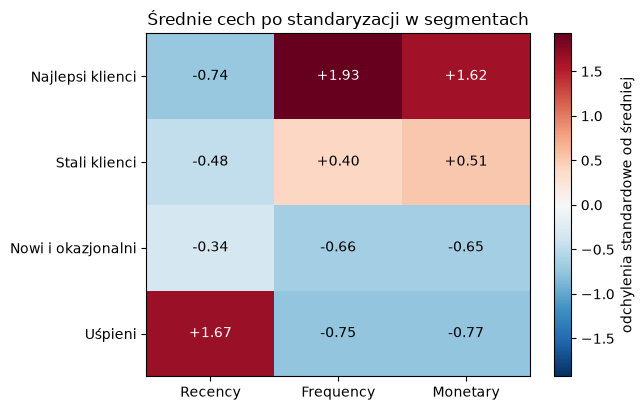

In [46]:
fig = wykresy.wykres_profili(wynik.X, segmenty["Segment"], NAZWY_SEGMENTOW)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "12_profile_segmentow.png")
fig

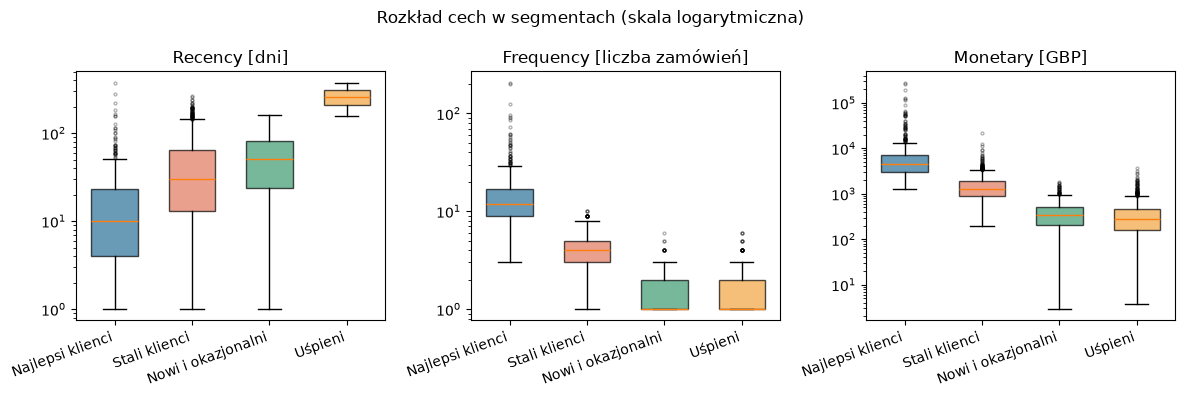

In [47]:
fig = wykresy.wykres_segmentow(segmenty, nazwy=NAZWY_SEGMENTOW)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "13_segmenty_rfm.png")
fig

Wariancja wyjaśniona przez PC1 i PC2: 93,7%


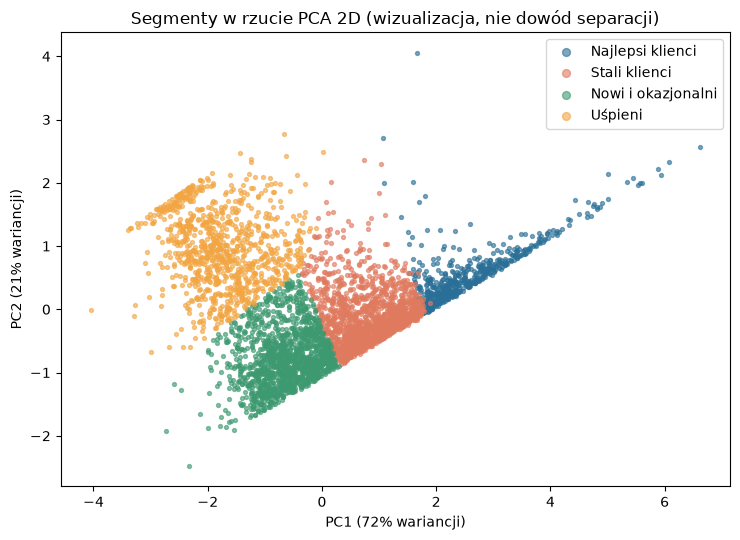

In [48]:
rzut, wariancja = rzut_pca(wynik.X, segmenty["Segment"])
print(f"Wariancja wyjaśniona przez PC1 i PC2: {wariancja.sum():.1%}".replace(".", ","))
fig = wykresy.wykres_pca(rzut, wariancja, NAZWY_SEGMENTOW)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "14_pca_segmenty.png")
fig

Rzut PCA zachowuje 93,7% wariancji trzech cech, więc dobrze oddaje ich układ, ale jest tylko
**wizualizacją**, a nie dowodem separacji w pełnej przestrzeni cech. Segmenty stykają się ze sobą –
klienci tworzą kontinuum, które K-means dzieli na części (co zgadza się z silhouette ≈ 0,38).
Pierwsza składowa (72% wariancji) to ogólny poziom aktywności i wartości (F i M rosną, Recency maleje),
a druga oddziela klientów nowych od dawno nieaktywnych.

### Charakterystyka segmentów

| Segment | Klienci | Udział w wartości | Mediany R / F / M | Opis |
|---|---|---|---|---|
| **0 – Najlepsi klienci** | 546 (12,6%) | 61,8% | 10 dni / 12 / 4 553 GBP | kupują często, niedawno i za duże kwoty; staż ok. 361 dni (od początku okresu), nikt nie jest klientem jednorazowym. Najpewniej odbiorcy hurtowi – priorytet utrzymania. |
| **1 – Stali klienci** | 1 446 (33,5%) | 27,5% | 30 dni / 4 / 1 298 GBP | regularni klienci o średniej wartości (staż ok. 270 dni); potencjał rozwoju w stronę najlepszych. |
| **2 – Nowi i okazjonalni** | 1 388 (32,1%) | 6,4% | 51 dni / 1 / 336 GBP | 56% zrobiło pierwszy zakup w ostatnich 90 dniach, 57% ma jedno zamówienie; celem jest drugi zakup. |
| **3 – Uśpieni** | 940 (21,8%) | 4,3% | 256 dni / 1 / 282 GBP | wszyscy nie kupowali od co najmniej 156 dni, 73% kupiło raz; klienci utraceni lub sezonowi. |

Segmenty 2 i 3 mają podobną częstotliwość i wartość zakupów – rozróżnia je Recency (oraz staż).

## 9. Wnioski i ograniczenia

**Odpowiedź na pytanie badawcze.** Na podstawie zachowań zakupowych można wyróżnić interpretowalne
segmenty klientów, ale ich granice są umowne: klienci tworzą kontinuum zaangażowania, które K-means
dzieli na cztery czytelne grupy (silhouette 0,38).

**Wnioski**

1. *Obserwacja:* 12,6% klientów (segment „Najlepsi klienci”) generuje 61,8% wartości zakupów netto.
   *Interpretacja:* utrzymanie tej niewielkiej grupy ma największe znaczenie dla przychodów sklepu.
2. *Obserwacja:* segmenty „Nowi i okazjonalni” oraz „Uśpieni” to 53,9% klientów, ale tylko 10,7%
   wartości; w obu dominują klienci z jednym zamówieniem.
   *Interpretacja:* największym wyzwaniem jest skłonienie klientów do drugiego zakupu; rozróżnienie
   nowych i uśpionych (Recency) pozwala zaadresować ich innymi działaniami.
3. *Obserwacja:* segmenty różnią się przede wszystkim ogólnym poziomem aktywności (pierwsza składowa
   PCA wyjaśnia 72% wariancji, F i M są silnie skorelowane).
   *Interpretacja:* trzy cechy RFM niosą w praktyce około dwóch wymiarów informacji: „ile i jak często”
   oraz „jak dawno”.
4. *Obserwacja:* bez transformacji cech K-means wydziela pojedynczych skrajnych klientów przy bardzo
   wysokim silhouette. *Interpretacja:* przygotowanie cech wpływa na wynik bardziej niż wybór między
   sąsiednimi wartościami k.

**Ograniczenia**

1. **Zakres danych:** jeden sklep i ok. 12 miesięcy; 25% transakcji bez identyfikatora klienta
   odrzucono. Wnioski dotyczą klientów obecnych w analizowanym zbiorze (zidentyfikowanych), a nie
   wszystkich klientów sklepu ani klientów w ogóle.
2. **Okno czasowe:** Recency zależy od daty odniesienia tuż po sezonie przedświątecznym; nie znamy
   historii sprzed grudnia 2010, więc „nowi” klienci mogą być klientami powracającymi.
3. **Definicje cech:** faktury anulujące nie są powiązane z oryginalnymi zamówieniami, więc zamówienie
   anulowane w całości nadal zwiększa Frequency; Monetary nie odróżnia klientów hurtowych od detalicznych.
4. **Metoda:** K-means zakłada sferyczne klastry podobnej wielkości, a wynik zależy od transformacji
   i skalowania cech; segmenty są podziałem kontinuum, a nie naturalnie oddzielonymi grupami.